# 08.1 · When deep learning wins, and when it does not

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/01-when-deep-learning-wins/lesson.ipynb)

Read the [README](README.md) first. This notebook runs one experiment: hand-made features against learning from raw pixels, on handwritten digits.

The deep-learning libraries are needed from this module on. If `import keras` fails, run `pip install -r setup/requirements-deep-learning.txt`.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. An image is a grid of numbers

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
images, labels = digits.images, digits.target          # 1,797 images, each 8×8
print(images.shape)
print(images[0].astype(int))

(1797, 8, 8)
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


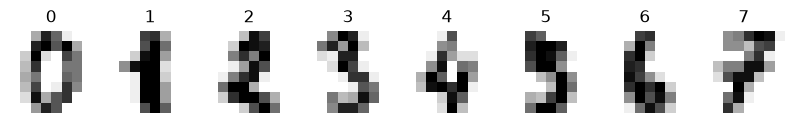

In [3]:
fig, axes = plt.subplots(1, 8, figsize=(10, 1.6))
for ax, img, lab in zip(axes, images, labels):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.show()

## 2. Hand-made features

The six features from the README: things a person might think distinguish digits.

In [4]:
def hand_features(img):
    """Six features a person might design for digit images."""
    return [img.mean(),                                 # average ink
            img[:4].mean() - img[4:].mean(),            # top minus bottom
            np.abs(img - img[:, ::-1]).mean(),          # left-right asymmetry
            (img > 4).sum(),                            # number of inked pixels
            img[:, :4].mean() - img[:, 4:].mean(),      # left minus right
            img[2:6, 2:6].mean()]                       # ink in the centre

H = np.array([hand_features(i) for i in images])
P = images.reshape(len(images), -1)                     # 64 raw pixels per image

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def logreg_accuracy(features):
    a, b, c, d = train_test_split(features, labels, test_size=0.25, random_state=42, stratify=labels)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(a, c)
    return model.score(b, d)

print(f"6 hand-made features → logistic regression accuracy: {logreg_accuracy(H):.1%}")

6 hand-made features → logistic regression accuracy: 68.0%


## 3. Let the model learn from the raw pixels

Same logistic regression, but now each of the 64 pixels is a column, so the model learns one weight per pixel per digit. Nobody designs anything.

In [6]:
print(f"64 raw pixels → logistic regression accuracy: {logreg_accuracy(P):.1%}")

64 raw pixels → logistic regression accuracy: 97.8%


Thirty points better. The model's 640 learned weights (64 pixels × 10 digits) capture more than six clever ideas did. That is the core of deep learning, taken further: **learn the features, do not design them.**

## 4. A small neural network

One hidden layer of 64 units, then 10 outputs (one per digit). You will understand every line of this by lesson 08.5; for now just look at the result.

In [7]:
import keras
from keras import layers
keras.utils.set_random_seed(42)      # same starting weights every run (small differences across machines are normal)
print("Keras", keras.__version__, "on", keras.backend.backend())

from keras import layers
a, b, c, d = train_test_split(P / 16, labels, test_size=0.25, random_state=42, stratify=labels)
net = keras.Sequential([keras.Input((64,)), layers.Dense(64, activation="relu"),
                        layers.Dense(10, activation="softmax")])
net.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
net.fit(a, c, epochs=30, verbose=0)
print(f"Neural network on raw pixels: {net.evaluate(b, d, verbose=0)[1]:.1%}")

Keras 3.15.1 on tensorflow


Neural network on raw pixels: 97.3%


About the same as logistic regression on pixels (the exact figure varies slightly by machine). On 8×8, centred, clean digits a linear model learning from pixels is already enough. The network pulls ahead when images are bigger and messier: clothing photos in 08.8, product photos in 08.9.

## 5. The honest scoreboard so far

| Problem | Data | Best simple model | Neural network |
|---|---|---|---|
| Churn (Module 05, lesson 08.5) | 5-column table | Logistic regression, AUC 0.741 | AUC 0.740 |
| Digits (this notebook) | 64 pixels | Logistic on pixels, 97.8% | about 97% |
| Clothing photos (08.8) | 784 pixels | | CNN, well ahead |
| Product photos (08.9, 08.P) | 150,528 numbers | | transfer learning |

## Quiz answers

1. **Structured** data has meaningful columns (ShopWave's customer table: orders, spend, days since last order). **Unstructured** data is raw signal where single units mean little (product photos, review text, support-call audio).
2. More than one hidden layer: several layers of learned features stacked on each other, each built from the one below.
3. Six numbers throw away almost everything about the shape. Different digits share the same averages and symmetry; the useful information is in *which* pixels are inked, which the features discard.
4. Any two of: a small table (boosting or logistic will match it), little labelled data and no pretrained model, a requirement to read the model's rules, tight compute.
5. 224 × 224 × 3 = 150,528.

**Next:** [08.2 One neuron](../02-one-neuron/)